# Review 2 -- Data Preprocessing and Exploratory Data Analysis
Food Waste Prediction and Meal-Planning Optimization for Event Catering

This notebook executes end to end from the raw CSV: data quality assessment, cleaning and validation, leakage-safe train/test partitioning, pre-event feature engineering, data integration (segment benchmark table), and exploratory data analysis.

In [1]:
%matplotlib inline
import sys, pathlib
ROOT = pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
import pipeline as P
get_ipython().run_line_magic('matplotlib', 'inline')  # pipeline.py forces the Agg backend on import
print('Loaded pipeline module from', P.__file__)

Loaded pipeline module from D:\PROJECTS\Mini Proj(PODS)\src\pipeline.py


## Section 1-2: Load raw data and run the data quality assessment

In [2]:
raw = P.load_raw()
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (1782, 11)


,type_of_food,number_of_guests,event_type,quantity_of_food,storage_conditions,purchase_history,seasonality,preparation_method,geographical_location,pricing,wastage_food_amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


In [3]:
dq = P.data_quality_assessment(raw)
print('Missing values:', dq['missing_values'])
print('Exact duplicates:', dq['exact_duplicates'])
print('Feature-duplicate conflict rows (same features, different target):', dq['feature_duplicate_conflict_rows'])
print('Records with quantity < guests:', dq['quantity_lt_guests'])
print('Distinct (guests, quantity) combinations:', dq['distinct_guest_qty_combos'])
print('Coverage of top 7 combinations: {}%'.format(dq['top7_combo_coverage_pct']))
print('Distinct target values:', dq['distinct_target_values'])
print('Target values divisible by 5: {}%'.format(dq['target_divisible_by_5_pct']))
dq['outlier_table']

Missing values: 0
Exact duplicates: 164
Feature-duplicate conflict rows (same features, different target): 94
Records with quantity < guests: 14
Distinct (guests, quantity) combinations: 61
Coverage of top 7 combinations: 68.4%
Distinct target values: 26
Target values divisible by 5: 86.2%


,column,outliers_1.5_iqr,outliers_3.0_iqr,z_gt_3,skew,kurtosis
0,number_of_guests,35,0,0,0.425,-0.508
1,quantity_of_food,0,0,0,-0.141,-1.111
2,wastage_food_amount,10,0,10,0.516,-0.257


In [4]:
register = P.build_dq_register(dq)
register

,id,issue,finding,action
0,DQ-01,Missing values,0 across all columns,No imputation required
1,DQ-02,Duplicate records,164 exact duplicates,Remove all; impact quantified
2,DQ-03,Feature-duplicate conflicts,"94 rows, identical features, differing target",Retain; used to bound attainable R2
3,DQ-04,Outliers,10 target values with |z|>3,Retain; influence tested
4,DQ-05,Cross-field logic,14 records with quantity < guests,Flag as unit ambiguity; retain
5,DQ-06,Encoding,UTF-8 BOM on header,Read with utf-8-sig; snake_case rename
6,DQ-07,Value granularity,61 combinations; 86.2% round targets,Recorded as a limitation
7,DQ-08,Class balance,max imbalance 7.65x,Note for effect-size interpretation


## Section 3: Cleaning and validation contract
All 164(+) exact duplicates are removed. A validation routine then enforces six invariants and raises an error (not a warning) if any is violated.

In [5]:
cleaned = P.clean(raw)
P.validate(cleaned)
print('Cleaned shape:', cleaned.shape)
print('All six validation invariants passed.')
ceiling = P.attainable_ceiling(cleaned)
ceiling

Cleaned shape: (1618, 11)
All six validation invariants passed.


{'dof_all_features': 58,
 'residual_variance_all_features': 26.845,
 'dof_strong_features': 1502,
 'residual_variance_strong_features': 7.264,
 'implied_r2_ceiling': 0.9328}

## Section 4: Partitioning before target-derived statistics
The 80/20 split happens **before** the LOW/MEDIUM/HIGH risk-tier cut points are computed, so no test-set value can influence a test-set label.

In [6]:
train_df, test_df = P.split(cleaned)
train_df, test_df, q1, q3 = P.derive_risk_tiers(train_df, test_df)
print(f'Train: {train_df.shape}, Test: {test_df.shape}')
print(f'Q1={q1}, Q3={q3}')
ks_stat, ks_p = stats.ks_2samp(train_df[P.TARGET], test_df[P.TARGET])
print(f'KS test train vs test target distribution: stat={ks_stat:.3f}, p={ks_p:.3f}')
print('\nTrain risk-tier distribution:')
print(train_df['risk_tier'].value_counts(normalize=True).round(3))
print('\nTest risk-tier distribution:')
print(test_df['risk_tier'].value_counts(normalize=True).round(3))

Train: (1294, 12), Test: (324, 12)
Q1=20.0, Q3=35.0
KS test train vs test target distribution: stat=0.046, p=0.635

Train risk-tier distribution:
risk_tier
MEDIUM    0.509
HIGH      0.342
LOW       0.150
Name: proportion, dtype: float64

Test risk-tier distribution:
risk_tier
MEDIUM    0.500
HIGH      0.364
LOW       0.136
Name: proportion, dtype: float64


## Section 4.3-4.4: Feature engineering, leakage checks, encoding

In [7]:
train_fe = P.engineer_features(train_df)
test_fe = P.engineer_features(test_df)
feature_cols = ['number_of_guests','quantity_of_food','food_per_guest','surplus_units',
                'pricing_ordinal','is_high_price','is_sit_down','guest_scale',
                'type_of_food','event_type','storage_conditions','purchase_history',
                'seasonality','geographical_location','preparation_method']
P.leakage_checks(feature_cols, train_fe, train_fe[P.TARGET])
print('Leakage checks passed: no target-derived feature name, no |r| > 0.95 with target.')
train_encoded, test_encoded, scaler, scale_cols = P.encode(train_fe, test_fe, feature_cols)
print('Design matrix columns:', train_encoded.shape[1])
train_fe[['food_per_guest','surplus_units','pricing_ordinal','is_high_price','is_sit_down','guest_scale']].head()

Leakage checks passed: no target-derived feature name, no |r| > 0.95 with target.


Design matrix columns: 33


,food_per_guest,surplus_units,pricing_ordinal,is_high_price,is_sit_down,guest_scale
0,1.245552,70,1,0,0,medium
1,1.394422,100,1,0,0,small
2,1.245552,70,0,0,0,medium
3,1.328904,100,1,0,0,medium
4,1.043182,20,0,0,0,very_large


## Section 5: Data integration -- segment benchmark table
A second relation, keyed on (pricing tier x preparation method), is derived from the **training partition only** and left-joined onto both partitions.

In [8]:
bench = P.build_benchmark_table(train_fe)
display(bench)
train_merged = P.merge_benchmark(train_fe, bench)
test_merged = P.merge_benchmark(test_fe, bench)
corr_train = train_merged['mean_waste'].corr(train_merged[P.TARGET])
corr_test = test_merged['mean_waste'].corr(test_merged[P.TARGET])
print(f'Correlation of benchmark mean with target -- train: {corr_train:.3f}, test: {corr_test:.3f}')
print('(Close agreement confirms no target leakage through the merge.)')

,pricing,preparation_method,mean_waste,median_waste,std_waste,n,mean_waste_per_guest,reliable
0,High,Buffet,36.012658,40.0,5.393476,79,0.113225,True
1,High,Finger Food,35.144068,35.0,8.107478,118,0.101341,True
2,High,Sit-down Dinner,41.453237,40.0,6.074416,278,0.115577,True
3,Low,Buffet,24.141026,26.5,9.993146,78,0.073172,True
4,Low,Finger Food,18.593496,20.0,3.674987,123,0.068252,True
5,Low,Sit-down Dinner,25.091603,25.0,7.971536,131,0.077114,True
6,Moderate,Buffet,26.966667,30.0,4.054571,60,0.081440,True
7,Moderate,Finger Food,20.148855,20.0,4.449458,262,0.072652,True
8,Moderate,Sit-down Dinner,24.593939,25.0,4.709742,165,0.083656,True


Correlation of benchmark mean with target -- train: 0.812, test: 0.801
(Close agreement confirms no target leakage through the merge.)


In [9]:
views = P.analytical_views(pd.concat([train_merged, test_merged], ignore_index=True))
for name, v in views.items():
    print(f"{name:24s} n={len(v):5d}  share={100*len(v)/(len(train_merged)+len(test_merged)):5.1f}%  mean_waste={v[P.TARGET].mean():.2f}")

high_risk_bookings       n=  560  share= 34.6%  mean_waste=40.52
premium_sit_down         n=  354  share= 21.9%  mean_waste=41.21
large_events_300plus     n= 1008  share= 62.3%  mean_waste=32.89
budget_finger_food       n=  155  share=  9.6%  mean_waste=18.55


## Section 6: Exploratory Data Analysis (training partition only)

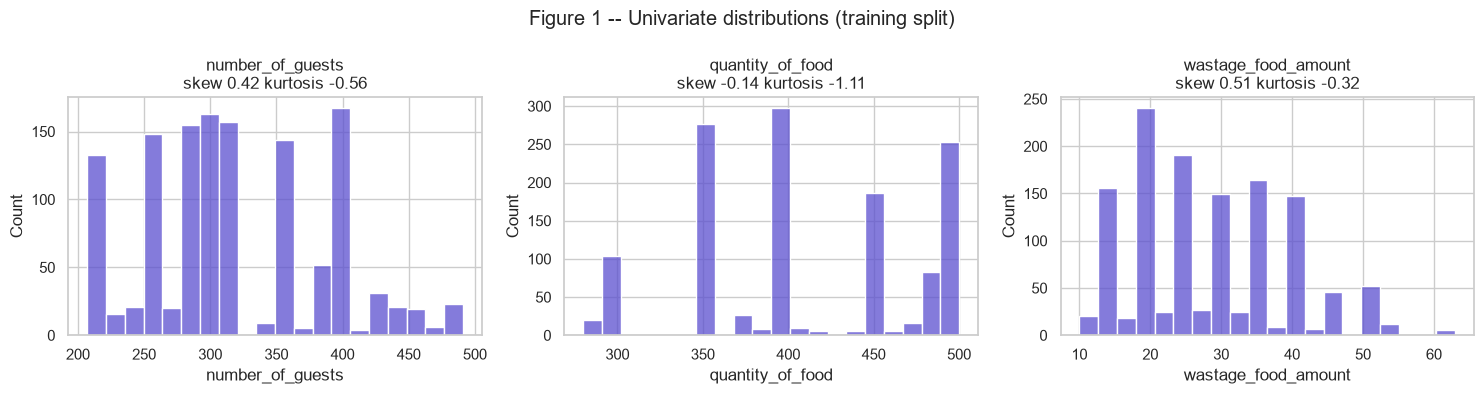

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['number_of_guests', 'quantity_of_food', P.TARGET]):
    sns.histplot(train_df[col], ax=ax, bins=20, color='#5B4FCF')
    ax.set_title(f'{col}\nskew {train_df[col].skew():.2f} kurtosis {train_df[col].kurtosis():.2f}')
fig.suptitle('Figure 1 -- Univariate distributions (training split)')
fig.tight_layout()
plt.show()

number_of_guests: r=0.650
quantity_of_food: r=0.641


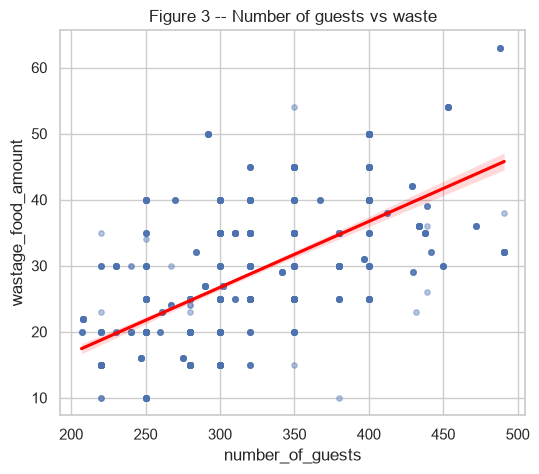

In [11]:
fig, ax = plt.subplots(figsize=(6,5))
for col in ['number_of_guests','quantity_of_food']:
    r = train_df[col].corr(train_df[P.TARGET])
    print(f'{col}: r={r:.3f}')
sns.regplot(x='number_of_guests', y=P.TARGET, data=train_df, ax=ax, scatter_kws={'alpha':0.4,'s':15}, line_kws={'color':'red'})
ax.set_title('Figure 3 -- Number of guests vs waste')
plt.show()

In [12]:
effect_rows = []
for col in P.CATEGORICAL_COLS:
    groups = [g[P.TARGET].values for _, g in train_df.groupby(col)]
    f_stat, p_anova = stats.f_oneway(*groups)
    h_stat, p_kw = stats.kruskal(*groups)
    grand_mean = train_df[P.TARGET].mean()
    ss_between = sum(len(g)*(g.mean()-grand_mean)**2 for g in groups)
    ss_total = ((train_df[P.TARGET]-grand_mean)**2).sum()
    eta2 = ss_between/ss_total
    effect_rows.append({'feature': col, 'k': len(groups), 'F': round(f_stat,2),
                         'anova_p': p_anova, 'kruskal_p': p_kw, 'eta2': round(eta2,4),
                         'effect': 'Large' if eta2>0.14 else ('Medium' if eta2>0.06 else 'Negligible')})
effect_df = pd.DataFrame(effect_rows).sort_values('eta2', ascending=False).reset_index(drop=True)
effect_df

,feature,k,F,anova_p,kruskal_p,eta2,effect
0,pricing,3,910.59,2.138113e-247,7.075425e-164,0.5852,Large
1,preparation_method,3,138.89,2.321793e-55,7.224490e-56,0.1771,Large
2,geographical_location,3,5.77,3.213503e-03,1.756220e-03,0.0089,Negligible
3,type_of_food,5,1.19,3.136292e-01,4.625686e-01,0.0037,Negligible
4,seasonality,3,1.62,1.973627e-01,1.758538e-01,0.0025,Negligible
5,event_type,4,0.51,6.760632e-01,6.145560e-01,0.0012,Negligible
6,purchase_history,2,0.82,3.663531e-01,4.368100e-01,0.0006,Negligible
7,storage_conditions,2,0.08,7.841571e-01,5.986723e-01,0.0001,Negligible


**Only pricing and preparation method show a detectable relationship with waste; the remaining six categorical features are negligible** -- this determines which features are worth keeping in Review 3's models.

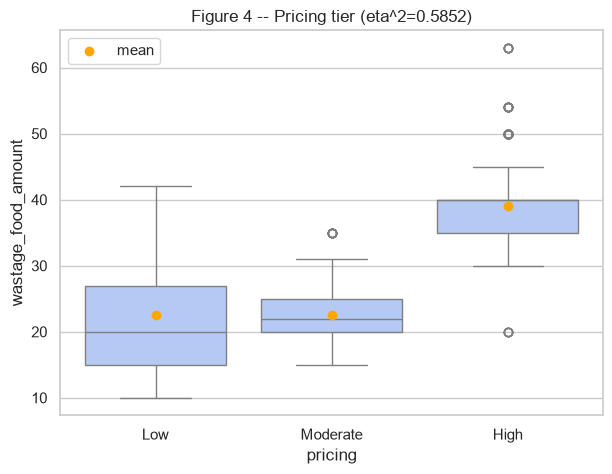

In [13]:
fig, ax = plt.subplots(figsize=(7,5))
order = train_df.groupby('pricing')[P.TARGET].mean().sort_values().index
sns.boxplot(x='pricing', y=P.TARGET, data=train_df, order=order, ax=ax, color='#A9C6FF')
means = train_df.groupby('pricing')[P.TARGET].mean().reindex(order)
ax.scatter(range(len(order)), means.values, color='orange', zorder=5, label='mean')
ax.legend()
ax.set_title(f"Figure 4 -- Pricing tier (eta^2={effect_df.set_index('feature').loc['pricing','eta2']:.4f})")
plt.show()

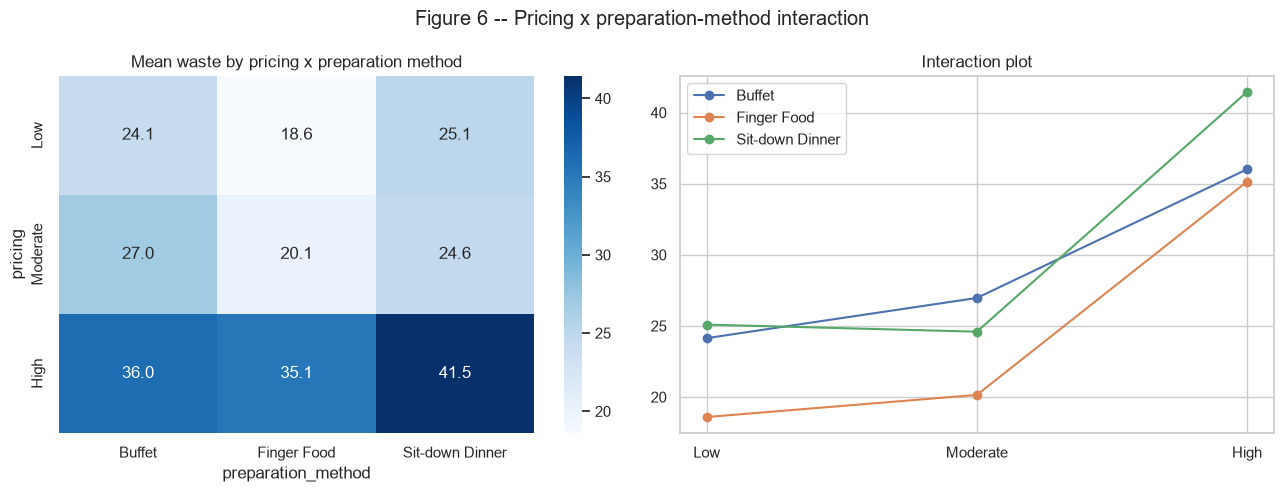

preparation_method,Buffet,Finger Food,Sit-down Dinner
pricing,,,
Low,24.141026,18.593496,25.091603
Moderate,26.966667,20.148855,24.593939
High,36.012658,35.144068,41.453237


In [14]:
pivot = train_df.pivot_table(index='pricing', columns='preparation_method', values=P.TARGET, aggfunc='mean').reindex(['Low','Moderate','High'])
fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Blues', ax=axes[0])
axes[0].set_title('Mean waste by pricing x preparation method')
for method in pivot.columns:
    axes[1].plot(pivot.index, pivot[method], marker='o', label=method)
axes[1].legend()
axes[1].set_title('Interaction plot')
fig.suptitle('Figure 6 -- Pricing x preparation-method interaction')
fig.tight_layout()
plt.show()
pivot

In [15]:
# Two-way interaction F-test (sequential least-squares ANOVA, valid for this unbalanced design)
import eda_extended as E
res = E.two_way_anova(train_df, 'pricing', 'preparation_method')
print(f"pricing: F={res['F_a']}  |  preparation_method given pricing: F={res['F_b']}  |  "
      f"interaction: F={res['F_ab']}, p={res['p_ab']:.2e}")

pricing: F=1105.87  |  preparation_method given pricing: F=118.34  |  interaction: F=11.54, p=3.28e-09


In [16]:
engineered = P.engineer_features(train_df)
corr_cols = ['number_of_guests','quantity_of_food','food_per_guest','surplus_units',
             'pricing_ordinal','is_high_price','is_sit_down', P.TARGET]
corr = engineered[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Figure 5 -- Pearson correlation matrix')
plt.show()

C:\Users\Ramanan\AppData\Local\Temp\ipykernel_14408\3057651156.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Section 6.4: Attainable predictive performance (irreducible-noise ceiling)
Rows that share an identical feature vector but record different target values bound how good any model can get -- no model can output two different predictions from one input.

In [17]:
print(ceiling)
print(f"\nImplied R2 ceiling from the 4 signal-carrying features: {ceiling['implied_r2_ceiling']}")

{'dof_all_features': 58, 'residual_variance_all_features': 26.845, 'dof_strong_features': 1502, 'residual_variance_strong_features': 7.264, 'implied_r2_ceiling': 0.9328}

Implied R2 ceiling from the 4 signal-carrying features: 0.9328


## Section 8: Export artefacts
Running `python src/pipeline.py` from the project root regenerates every CSV in `out/` and every figure in `figures/` referenced in the Review 2 report.

In [18]:
print('out/ files already written by src/pipeline.py:')
for p in sorted((ROOT / 'out').glob('*.csv')):
    print(' -', p.name)

out/ files already written by src/pipeline.py:
 - categorical_effect_sizes.csv
 - classification_baseline_metrics.csv
 - classification_model_comparison.csv
 - classification_report_best_model.csv
 - classification_tuning_before_after.csv
 - cleaned_event_catering.csv
 - confusion_matrix_best_model.csv
 - cv_fold_scores.csv
 - data_quality_register.csv
 - eda_category_summary.csv
 - eda_cramers_v_matrix.csv
 - eda_numeric_summary.csv
 - eda_risk_tier_association.csv
 - eda_two_way_anova.csv
 - feature_importance.csv
 - feature_importance_final_classifier.csv
 - feature_importance_final_regressor.csv
 - final_model_significance.csv
 - key_insights.csv
 - model_selection_rationale.csv
 - per_class_metrics_all_models.csv
 - regression_baseline_metrics.csv
 - regression_model_comparison.csv
 - regression_tuning_before_after.csv
 - segment_benchmark_table.csv
 - view_budget_finger_food.csv
 - view_high_risk_bookings.csv
 - view_large_events_300plus.csv
 - view_premium_sit_down.csv
 - vif_ta